In [1]:
import os
import sys
os.system('export HF_DATASETS_CACHE="/data/cache/huggingface"')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scipy.stats as stats
import torch
import datasets
from datetime import datetime, timezone
import numpy as np
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
import h5py
sns.set_theme()
import pygmt
from scipy.interpolate import interp1d

In [4]:
catalog_train = datasets.load_dataset("./ncedc_catalog.py", split="train", name="event", cache_dir="/data/cache/huggingface")
# catalog = catalog.filter(lambda x: x["num_stations"] >= 5)
catalog_train = catalog_train.with_format("pandas")

Extracting data files:   0%|          | 0/16 [00:00<?, ?it/s]

['/data/cache/huggingface/downloads/cd85e327478000b37c75af9b94c074a9bbd74b8a15238386734d95ef4fae4cdc', '/data/cache/huggingface/downloads/02132c57ca1ac8f3a35cd46a0d596476125ef1feace840b6f445b44e2619598f', '/data/cache/huggingface/downloads/61eee1bfde48a08aca5e08d8e9360aa73c8d680223006eaf7b9a7ce106e5be83', '/data/cache/huggingface/downloads/c964204359c26f69a59f9fb2a9bf076292d7b27603cea969e69c24ef964de081', '/data/cache/huggingface/downloads/55b2b45bc60d8d34d05fcbdf277e3372d84797689d8aebae9d48efed0d387c74', '/data/cache/huggingface/downloads/ad1c657945e4aeb2dcbea950760fb78a8f06515e2b29c0df2dff664007709437', '/data/cache/huggingface/downloads/e699a287864042e76eae3975a5f28d7bf4039a600f46b8eb5c7d5159c78fe1ea', '/data/cache/huggingface/downloads/3f9d57ff98510cf46920180438c120c553b82d83fafe13d88e8a8776be8c5e97', '/data/cache/huggingface/downloads/39749a2c5554bb62aa6518edc25d835bcc1a37e88381363c47b5f6155446f6ae', '/data/cache/huggingface/downloads/de149bb67e40d4174eada362f8b8e2f2e63a03136b0daa

Generating train split: 0 examples [00:00, ? examples/s]

KeyboardInterrupt: 

In [15]:
catalog_test = datasets.load_dataset("./ncedc_catalog.py", split="test", name="event_test", cache_dir="/data/cache/huggingface")
catalog_test = catalog_test.with_format("pandas")

Found cached dataset ncedc_catalog (/data/cache/huggingface/ncedc_catalog/event_test/1.1.0/040cdce2c415dcd39a120550046fda2de8c0f57a7c4bb0f798c7bd526d29e2d3)


In [9]:
catalog_test

Dataset({
    features: ['event_id', 'num_stations', 'origin_time', 'longitude', 'latitude', 'depth_km', 'magnitude', 'magnitude_type', 'station_ids', 'station_location', 'station_dist_azi', 'picks', 'dt_s'],
    num_rows: 16211
})

In [10]:
catalog_test["magnitude"]

0       -0.15
1        0.94
2        0.65
3        0.88
4        1.03
         ... 
16206    1.04
16207   -0.13
16208    2.33
16209    2.26
16210    1.61
Name: magnitude, Length: 16211, dtype: float32

In [16]:
catalog_test.select_columns(["magnitude"]).with_format("numpy")["magnitude"]

array([-0.15,  0.94,  0.65, ...,  2.33,  2.26,  1.61], dtype=float32)

In [62]:
catalog_custom = datasets.load_dataset("./ncedc_catalog.py", split="train", name="event_custom", cache_dir="/data/cache/huggingface", data_files="/nfs/quakeflow_dataset/NCEDC/2020.h5")
catalog_custom.set_format("pandas")
catalog_custom = catalog_custom.data.to_pandas()

Found cached dataset ncedc_catalog (/data/cache/huggingface/ncedc_catalog/event_custom-3186f49981dc20f6/1.1.0/040cdce2c415dcd39a120550046fda2de8c0f57a7c4bb0f798c7bd526d29e2d3)


# brief

In [64]:
import copy

catalog=copy.deepcopy(catalog_custom)

In [97]:
catalog=copy.deepcopy(catalog_test)

In [98]:
#catalog = catalog[catalog["num_stations"] >= 5]
catalog["event_id"] = catalog["event_id"].astype(str)
catalog["magnitude_type"] = catalog["magnitude_type"].astype(str)
catalog["magnitude"] = catalog["magnitude"].astype(float)
# previous time data format like this: 2020-01-23T09:53:29.650000+00:00
catalog["origin_time"] = pd.to_datetime(catalog["origin_time"].str[:19], format="%Y-%m-%dT%H:%M:%S")
catalog["latitude"] = catalog["latitude"].astype(float)
catalog["longitude"] = catalog["longitude"].astype(float)
catalog["depth_km"] = catalog["depth_km"].astype(float)
catalog.keys()

Index(['event_id', 'num_stations', 'origin_time', 'longitude', 'latitude',
       'depth_km', 'magnitude', 'magnitude_type', 'station_ids',
       'station_location', 'station_dist_azi', 'picks', 'dt_s'],
      dtype='object')

In [99]:
selected_columns = catalog[["event_id", "num_stations", "origin_time", "longitude", "latitude", "depth_km", "magnitude", 'magnitude_type']]
selected_columns

,event_id,num_stations,origin_time,longitude,latitude,depth_km,magnitude,magnitude_type
0,nc71111584,2,2020-01-02 07:01:48,-118.879799,37.654499,3.690000,-0.15,D
1,nc71111589,8,2020-01-07 21:59:32,-121.517502,40.469700,2.500000,0.94,D
2,nc71111594,5,2020-01-09 10:58:03,-121.750298,37.412300,5.090000,0.65,D
3,nc71111599,1,2020-01-10 07:22:58,-118.774300,37.472801,8.910000,0.88,D
4,nc71111679,9,2020-01-07 22:26:44,-123.338699,39.404800,3.980000,1.03,D
...,...,...,...,...,...,...,...,...
16206,nc73505310,6,2020-12-31 20:32:43,-123.262001,39.357700,4.180000,1.04,D
16207,nc73505325,1,2020-12-31 22:20:13,-122.767197,38.789200,2.170000,-0.13,D
16208,nc73505335,3,2020-12-31 22:37:31,-117.761002,38.151699,10.520000,2.33,D
16209,nc73505340,15,2020-12-31 22:43:07,-124.230301,40.451500,20.450001,2.26,D


In [36]:
selected_columns.iloc[27]


event_id                          nc71111984
num_stations                               1
origin_time       2020-02-15 13:59:12.800000
longitude                        -118.869003
latitude                             37.6637
depth_km                                2.82
magnitude                               0.32
magnitude_type                             D
Name: 27, dtype: object

In [100]:
num_stas = catalog['num_stations'].values
sta_locs = catalog['station_location'].values

station_locations = catalog['station_location'].values[0]
station_locations = np.unique(station_locations, axis=0)
for i in tqdm(range(1, len(num_stas))):
    station_locations = np.concatenate([station_locations, np.unique(catalog['station_location'].values[i], axis=0)], axis=0)
    if i % 1000 == 0:
        station_locations = np.unique(station_locations, axis=0)
        
station_locations = np.unique(station_locations, axis=0)

# Print the collected station locations
print(station_locations.shape)
station_locations[:10]

 41%|████      | 6586/16210 [00:00<00:00, 22675.98it/s]

100%|██████████| 16210/16210 [00:00<00:00, 22516.88it/s]

(722, 3)


array([[-1.243544e+02,  4.054410e+01, -1.800000e-01],
       [-1.243426e+02,  4.028840e+01, -5.000000e-02],
       [-1.243375e+02,  4.047560e+01, -3.800000e-01],
       [-1.243342e+02,  4.287240e+01, -8.500000e-01],
       [-1.242945e+02,  4.049760e+01, -7.500000e-01],
       [-1.242877e+02,  4.032500e+01, -4.000000e-02],
       [-1.242843e+02,  4.032200e+01, -4.000000e-02],
       [-1.242660e+02,  4.025670e+01, -8.900000e-01],
       [-1.242637e+02,  4.057620e+01, -2.000000e-02],
       [-1.242260e+02,  4.221240e+01, -1.010000e+00]], dtype=float32)

In [101]:
event_locations = catalog[['longitude', 'latitude', 'depth_km']].values
event_locations[:10]

array([[-118.87979889,   37.65449905,    3.69000006],
       [-121.51750183,   40.46969986,    2.5       ],
       [-121.75029755,   37.41230011,    5.09000015],
       [-118.77429962,   37.47280121,    8.90999985],
       [-123.33869934,   39.40480042,    3.98000002],
       [-118.83499908,   37.55619812,   -1.22000003],
       [-118.89779663,   37.43830109,    3.03999996],
       [-119.02220154,   37.62580109,    1.21000004],
       [-118.91280365,   37.63869858,    5.01000023],
       [-119.02500153,   37.63679886,    0.38      ]])

In [102]:
min_lon, max_lon = station_locations[:, 0].min(), station_locations[:, 0].max()
min_lon, max_lon = min(min_lon, catalog['longitude'].min()), max(max_lon, catalog['longitude'].max())
min_lat, max_lat = station_locations[:, 1].min(), station_locations[:, 1].max()
min_lat, max_lat = min(min_lat, catalog['latitude'].min()), max(max_lat, catalog['latitude'].max())

min_lon, max_lon, min_lat, max_lat

(-127.28500366210938, -115.24500274658203, 34.0382, 42.8882)

makecpt [WARNING]: Without inc in -T option, -Z has no effect (ignored)


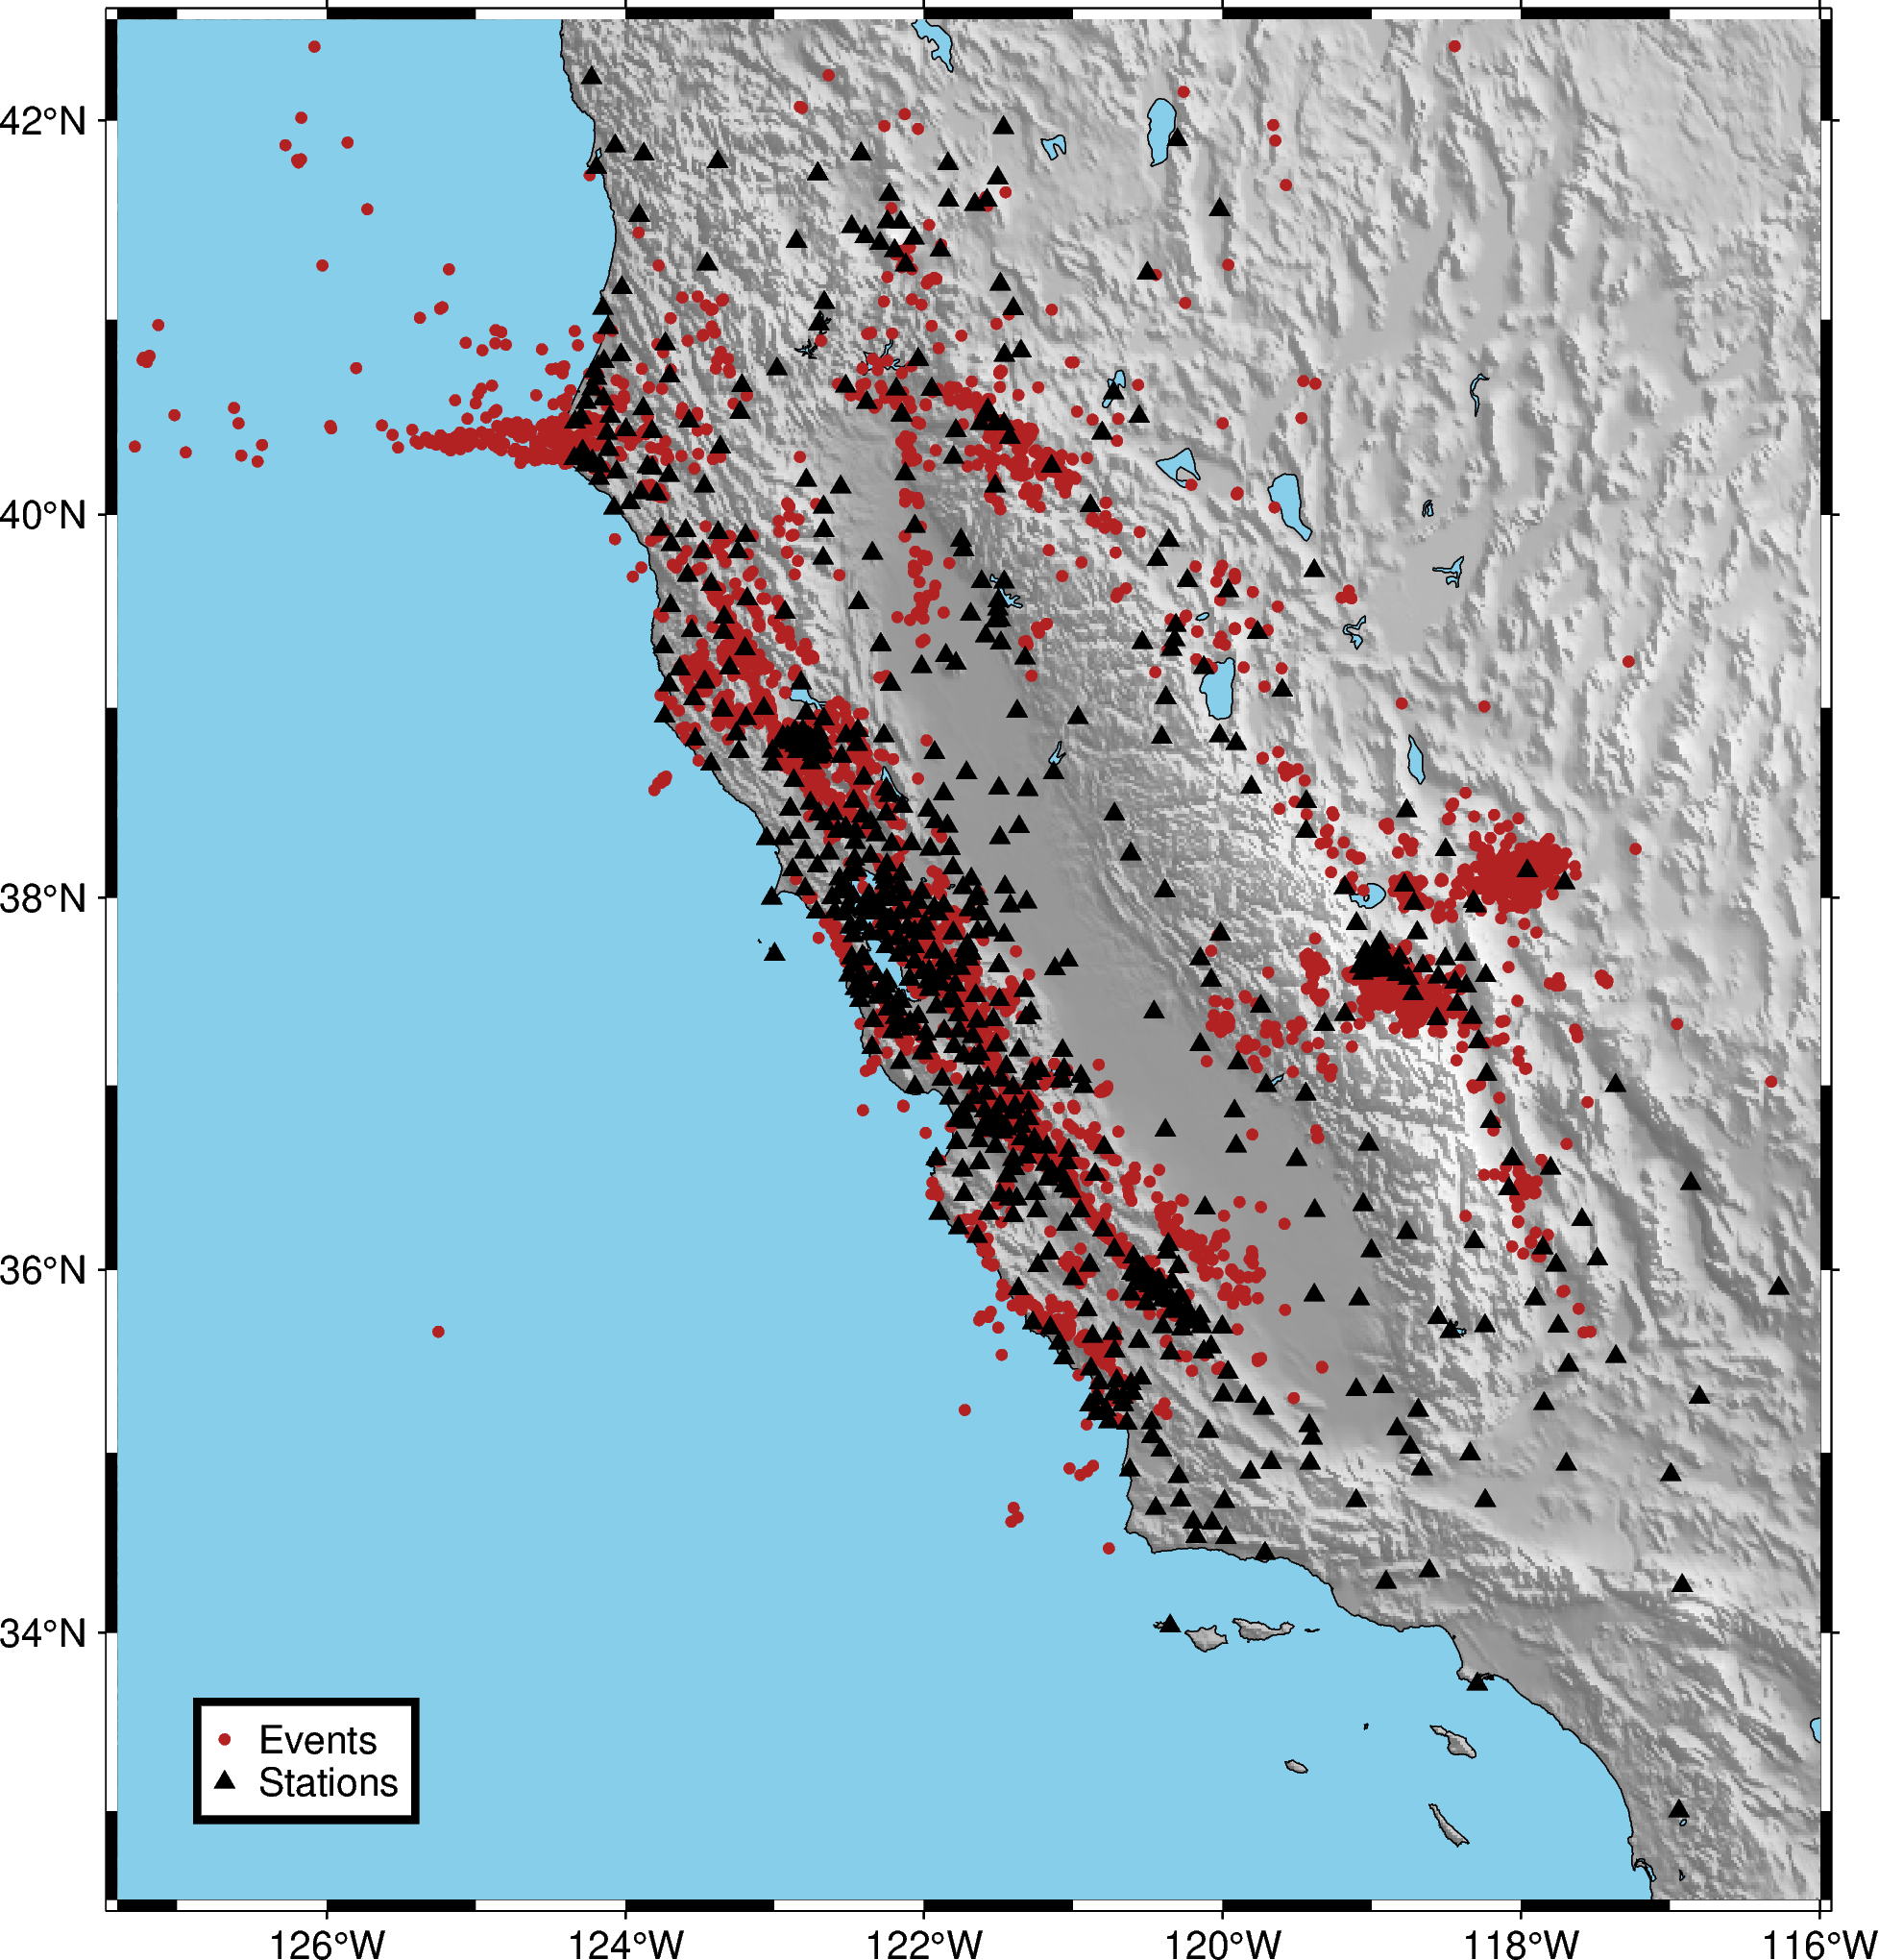

In [84]:
min_lon_lim, max_lon_lim = round(min_lon - 0.1, 1), round(max_lon + 0.1, 1)
min_lat_lim, max_lat_lim = round(min_lat - 0.1, 1), round(max_lat + 0.1, 1)

max_lon_lim=-116.0
min_lat_lim=32.5
max_lat_lim=42.5

# Define the map region
region = f"{min_lon_lim}/{max_lon_lim}/{min_lat_lim}/{max_lat_lim}"

# Create a new figure
fig = pygmt.Figure()

cpt = pygmt.makecpt(cmap="gray", series=[100, 200], continuous=True)

grid = pygmt.datasets.load_earth_relief(region=region, resolution="01m", registration="gridline")
fig.basemap(region=region, projection="M15c", frame=["af"])
# fig.coast(shorelines=True, water="skyblue", land="gray", projection="M15c")

grad = pygmt.grdgradient(grid=grid, azimuth=45, normalize="e0.5")
# fig.grdimage(grid=grid, cmap="geo", shading=True)
fig.grdimage(grid=grid, cmap="gray", transparency=75, projection="M15c", shading=grad)
fig.coast(shorelines=True, water="skyblue", projection="M15c")

# Plot the events as circles
fig.plot(
    data=event_locations[:, :2],
    style="c0.1c",
    fill="#B22222",
    label="Events",
)

# Plot the stations as triangles
fig.plot(
    data=station_locations[:, :2],
    style="t0.2c",
    fill="black",
    pen="black",
    label="Stations",
)

fig.legend(position="JBL+jBL+o0.7c", box="+gwhite+p2p,black")

# Show the figure
fig.show()


In [103]:
epicentral_distances = []

for i, (event_loc, station_loc) in enumerate(zip(event_locations, sta_locs)):
    event_loc_rad = np.radians(event_loc)
    station_loc_rad = np.radians(station_loc)
    dlon = event_loc_rad[0] - station_loc_rad[:, 0]
    dlat = event_loc_rad[1] - station_loc_rad[:, 1]
    a = np.sin(dlat / 2)**2 + np.cos(event_loc_rad[1]) * np.cos(station_loc_rad[:, 1]) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a)) * 6371
    epicentral_distances.append(c)
    if c.max() > 5000:
        print(i, c.max())
    
epicentral_distances = np.concatenate(epicentral_distances, axis=0)

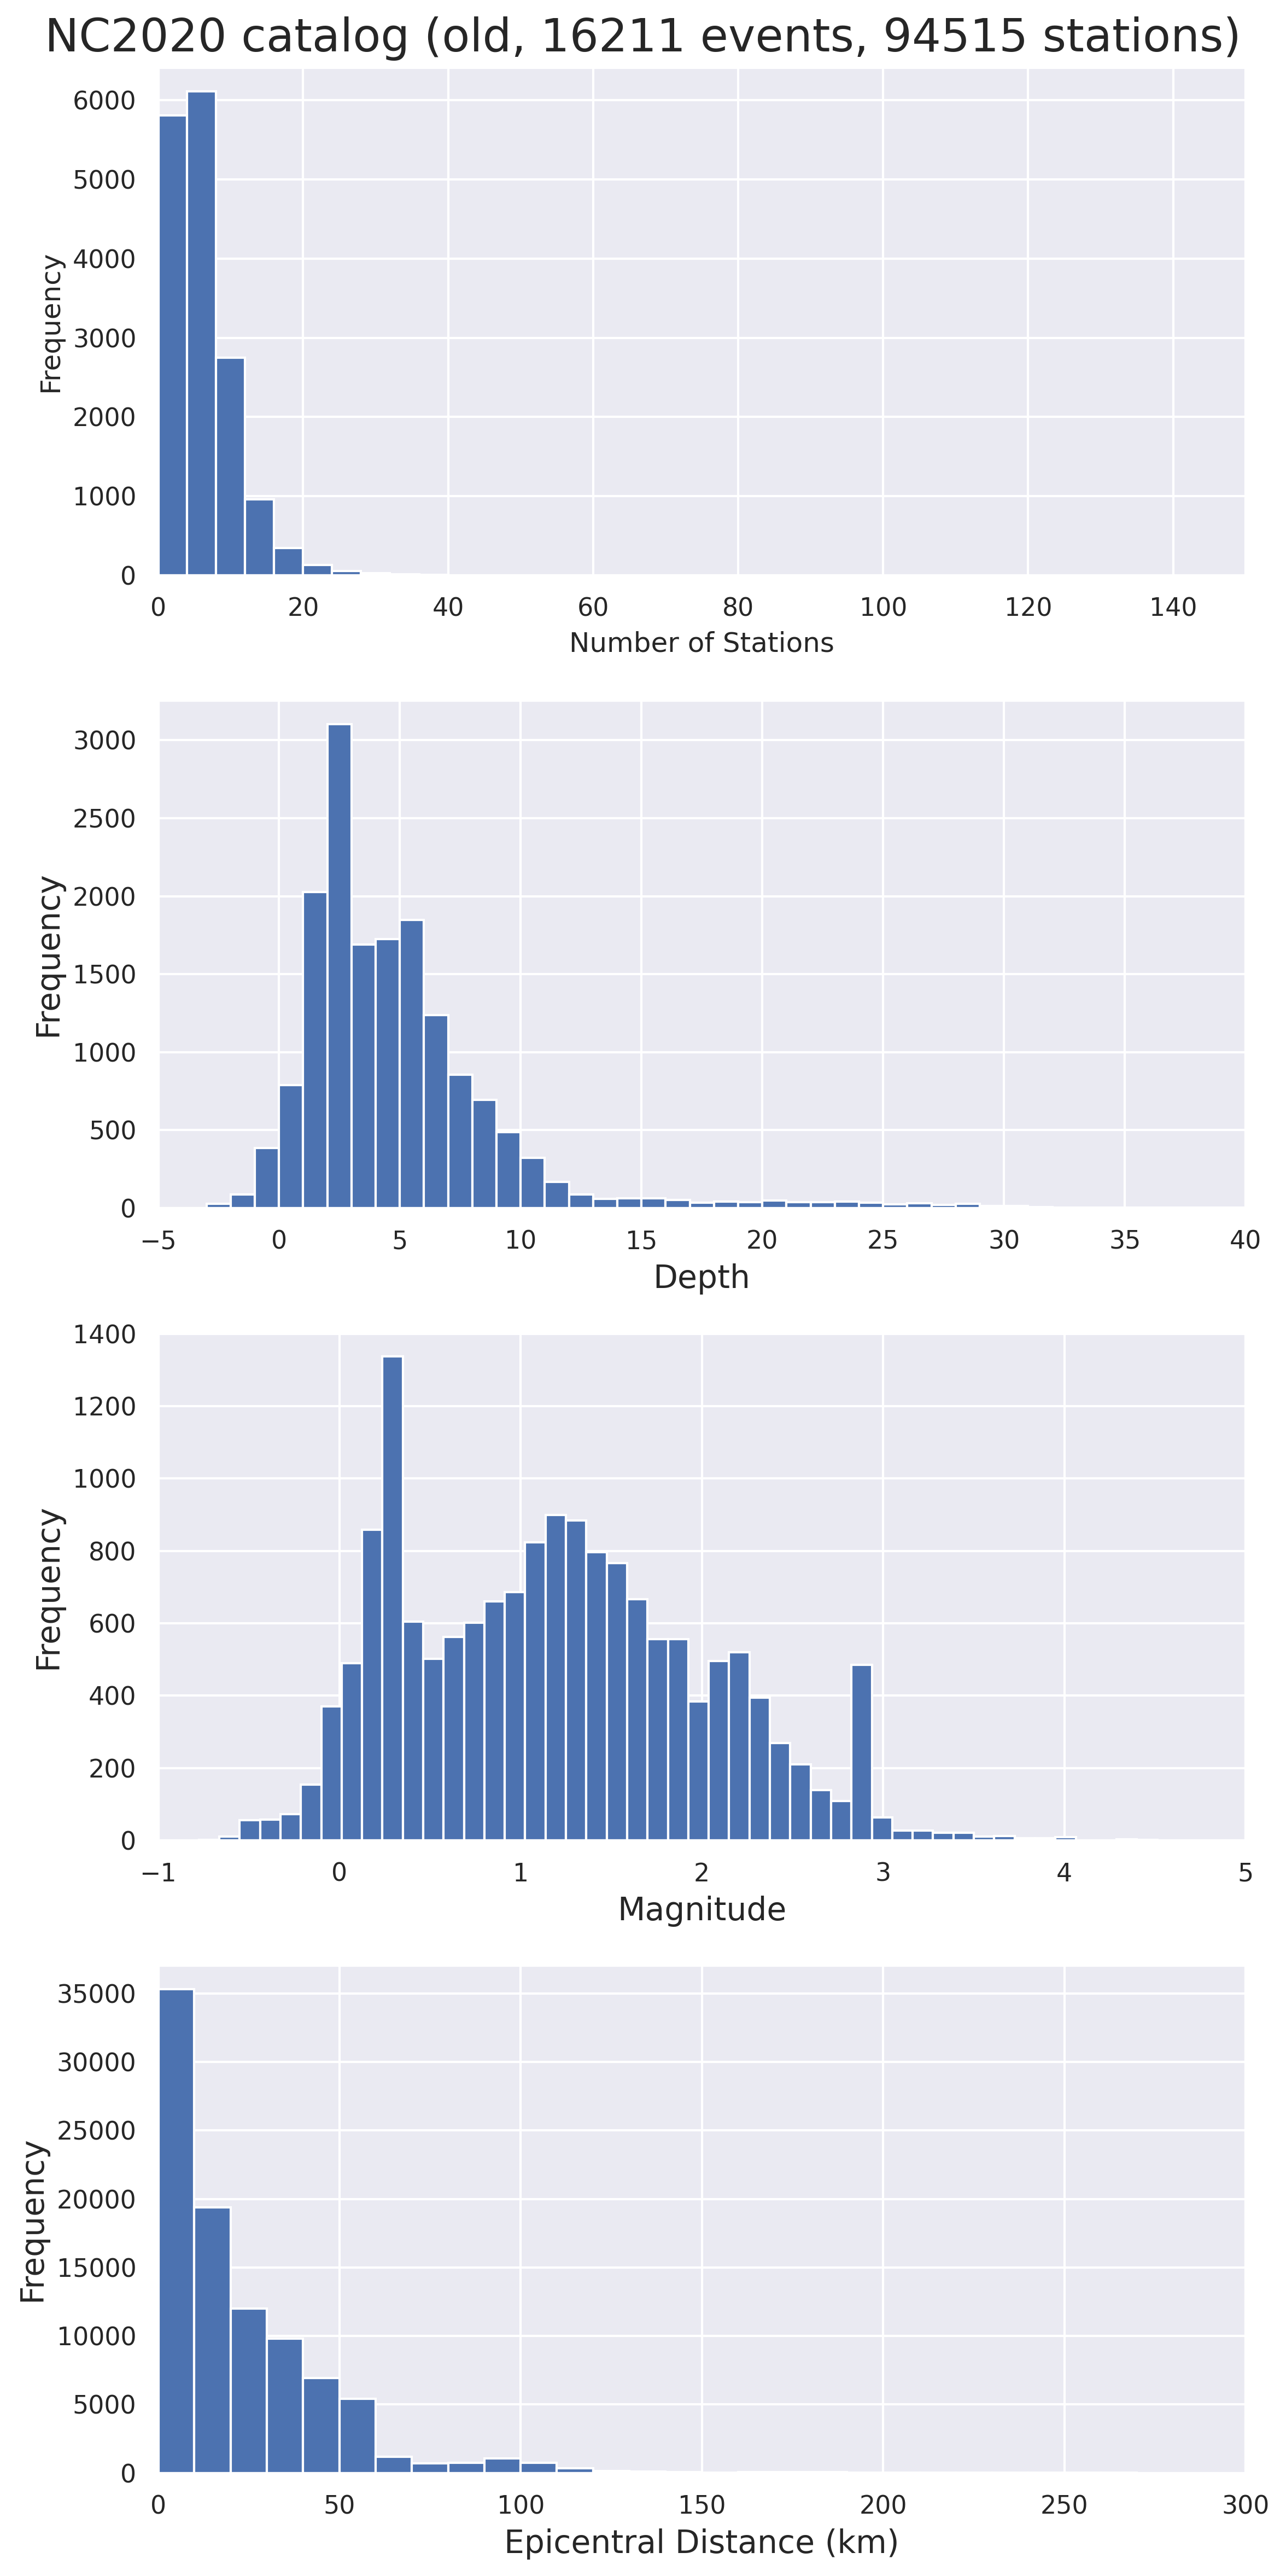

In [104]:
# Create a figure with two subplots
fig, axes = plt.subplots(4, 1, figsize=(8, 16), dpi=300)

# Plot the histogram for the "num_stations" column
axes[0].hist(catalog["num_stations"], range=(0,100), bins=25, color="C0")
axes[0].set_xlim(0, 150)  # Set x-axis range
axes[0].set_xlabel("Number of Stations")
axes[0].set_ylabel("Frequency")
#axes[0].set_title("Stations per event distribution", fontsize=16)

# Plot the histogram for the "depth_km" column
axes[1].hist(catalog["depth_km"], range=(-10, 50), bins=60, color="C0")
axes[1].set_xlabel("Depth", fontsize=14)
axes[1].set_ylabel("Frequency", fontsize=14)
#axes[1].set_title("Depth distribution", fontsize=16)
axes[1].set_xlim(-5, 40)  # Set x-axis range

# Plot the histogram for the "magnitude" column
axes[2].hist(catalog["magnitude"], range=(-1, 8), bins=80, color="C0")
axes[2].set_xlabel("Magnitude", fontsize=14)
axes[2].set_ylabel("Frequency", fontsize=14)
#axes[2].set_title("Magnitude distribution", fontsize=16)
axes[2].set_xlim(-1, 5)  # Set x-axis range

# Plot the histogram for the "epicentral_distance"
axes[3].hist(epicentral_distances, range=(0, 500), bins=50, color="C0")
axes[3].set_xlabel("Epicentral Distance (km)", fontsize=14)
axes[3].set_ylabel("Frequency", fontsize=14)
#axes[2].set_title("Epicentral distance distribution", fontsize=16)
axes[3].set_xlim(0, 300)  # Set x-axis range

plt.suptitle(f"NC2020 catalog (old, {len(catalog)} events, {catalog['num_stations'].values.sum()} stations)", fontsize=20)
# Adjust the spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()
